# When does Yarkovsky become detectable?

**The question.** The Yarkovsky drift is a tiny acceleration (~$10^{-14}$ au/day² for a
500 m asteroid), but its effect on the along-track position grows *quadratically* with time. So
for any asteroid there is an arc length at which the drift stops hiding inside the observation
noise. How long is that for Bennu, and what does radar buy?

**The experiment.** Pretend it is an earlier year: keep only the observations made before
1 January of that year, fit, and measure the transverse coefficient $A_2$ and its uncertainty.
Repeat for a ladder of years. We measure $A_2$ two ways at every cut:

* **optical only** — the gravity fit, then the same observations re-fitted with $A_2$ free;
* **optical + radar** — that orbit and $A_2$ re-solved jointly with every radar delay/Doppler
  measurement available by then.

We also record whether PyRoOrb's *automatic* model selection (what `fit_orbit` does by default)
would have switched the Yarkovsky model on.

In [1]:
# Load the PyRoOrb settings file (.env: data folders) before the engine is imported.
from pyroorb.envfile import load_env_file
load_env_file()

import warnings
import numpy as np
import matplotlib.pyplot as plt
import pyroorb

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


In [2]:
from astropy.time import Time
from pyroorb import fit_object, radar      # internal modules (may change): forced model, radar joint

obs = pyroorb.fetch_observations("101955")
oc = pyroorb.obscodes()
print(len(obs), "optical observations,", len(obs.meta["radar"]), "radar measurements")

603 optical observations, 29 radar measurements


## The ladder

Each step is two or three fits of a few hundred observations: a few seconds each.
`refine_nongrav(..., model="yarkovsky")` forces the $A_2$ model on a fixed observation set;
`radar.refine_radar` is the joint optical + radar solve that `fit_orbit` runs whenever radar exists.

In [3]:
YEARS = [2001, 2006, 2009, 2012, 2014, 2019, 2024, 2027]      # 2027 = all the data
rows = []
for year in YEARS:
    cut = Time(f"{year}-01-01").jd
    rad = [r for r in obs.meta["radar"] if r["jd_utc"] < cut]
    sub = pyroorb.Observations([o for o in obs if o["jd_utc"] < cut], {**obs.meta, "radar": rad})

    auto = pyroorb.fit_orbit(sub, designation="101955")           # the default, automatic fit
    grav = (auto if auto.nongrav_model is None else
            fit_object.fit_orbit(list(sub), oc, desig="101955", meta=sub.meta, auto_nongrav=False))
    opt = fit_object.refine_nongrav(grav, model="yarkovsky", revert_if_worse=False)
    joint = radar.refine_radar(opt, rad, oc) if rad else opt

    rows.append(dict(year=year, n_obs=len(sub), n_radar=len(rad), arc=grav.arc_length_days() / 365.25,
                     auto=auto.nongrav_model,
                     a2_opt=opt.nongrav_params["A2"], s_opt=opt.nongrav_sigmas["A2"],
                     a2_rad=joint.nongrav_params["A2"], s_rad=joint.nongrav_sigmas["A2"]))
    r = rows[-1]
    print(f"to {year}: {r['n_obs']:3d} obs + {r['n_radar']:2d} radar, arc {r['arc']:4.1f} yr | "
          f"optical A2 = {r['a2_opt']:+.2e} ± {r['s_opt']:.1e} | "
          f"+radar A2 = {r['a2_rad']:+.3e} ± {r['s_rad']:.1e} | auto model: {r['auto']}")

to 2001: 217 obs + 10 radar, arc  0.6 yr | optical A2 = -6.97e-11 ± 6.3e-11 | +radar A2 = -9.002e-13 ± 1.3e-11 | auto model: None


to 2006: 266 obs + 23 radar, arc  6.0 yr | optical A2 = -7.84e-14 ± 1.1e-13 | +radar A2 = -3.176e-14 ± 5.5e-15 | auto model: None


to 2009: 293 obs + 23 radar, arc  6.7 yr | optical A2 = +1.17e-13 ± 1.0e-13 | +radar A2 = -3.791e-14 ± 5.8e-15 | auto model: None


to 2012: 463 obs + 29 radar, arc 12.2 yr | optical A2 = -2.87e-14 ± 8.0e-15 | +radar A2 = -4.380e-14 ± 8.7e-17 | auto model: None


to 2014: 569 obs + 29 radar, arc 13.4 yr | optical A2 = -1.18e-14 ± 4.6e-15 | +radar A2 = -4.394e-14 ± 2.2e-16 | auto model: None


to 2019: 580 obs + 29 radar, arc 18.7 yr | optical A2 = -2.42e-14 ± 3.7e-15 | +radar A2 = -4.399e-14 ± 2.3e-16 | auto model: None


to 2024: 585 obs + 29 radar, arc 24.1 yr | optical A2 = -2.41e-14 ± 3.6e-15 | +radar A2 = -4.399e-14 ± 2.3e-16 | auto model: None


to 2027: 603 obs + 29 radar, arc 25.6 yr | optical A2 = -2.65e-14 ± 2.7e-15 | +radar A2 = -4.398e-14 ± 2.4e-16 | auto model: yarkovsky


## The picture

reference A2 = -4.557e-14 au/day^2


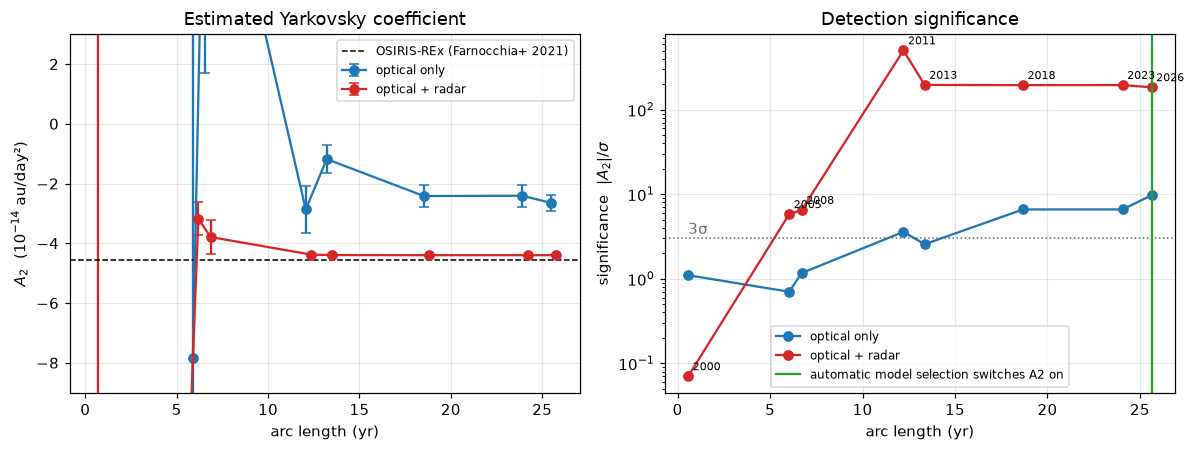

In [4]:
# Reference: OSIRIS-REx drift da/dt = -284.6 m/yr (Farnocchia et al. 2021), turned into the
# equivalent A2 with the orbit-averaged relation da/dt = 2 A2 / (n a^2 (1-e^2)) (r0 = 1 au)
el = auto.elements()                       # the last, full-arc fit
REF_A2 = (-284.6 / (1.495978707e11 * 365.25)) * np.radians(el["n"]) * el["a"]**2 * (1 - el["e"]**2) / 2
print(f"reference A2 = {REF_A2:.3e} au/day^2")
arc = np.array([r["arc"] for r in rows])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

for key, skey, label, c, dx in (("a2_opt", "s_opt", "optical only", "C0", -0.15),
                                ("a2_rad", "s_rad", "optical + radar", "C3", 0.15)):
    a = np.array([r[key] for r in rows]); s = np.array([r[skey] for r in rows])
    ax1.errorbar(arc + dx, a * 1e14, yerr=s * 1e14, fmt="o-", capsize=3, color=c, label=label)
    ax2.semilogy(arc, np.abs(a) / s, "o-", color=c, label=label)
ax1.axhline(REF_A2 * 1e14, color="k", ls="--", lw=1, label="OSIRIS-REx (Farnocchia+ 2021)")
ax1.set_ylim(-9, 3); ax1.set_xlabel("arc length (yr)"); ax1.set_ylabel(r"$A_2$  ($10^{-14}$ au/day²)")
ax1.set_title("Estimated Yarkovsky coefficient"); ax1.legend(fontsize=8)

ax2.axhline(3, color="0.4", ls=":", lw=1); ax2.text(arc[0], 3.4, "3σ", color="0.4")
fired = [r["arc"] for r in rows if r["auto"]]
if fired:
    ax2.axvline(min(fired), color="C2", lw=1.5, label="automatic model selection switches A2 on")
ax2.set_xlabel("arc length (yr)"); ax2.set_ylabel(r"significance  $|A_2| / \sigma$")
ax2.set_title("Detection significance"); ax2.legend(fontsize=8)
for r in rows:
    ax2.annotate(str(r["year"] - 1), (r["arc"], abs(r["a2_rad"]) / r["s_rad"]), fontsize=7,
                 textcoords="offset points", xytext=(3, 4))
plt.tight_layout(); plt.show()

## What it shows

* **Radar is the lever.** With the 1999 and 2005 radar ranging, $A_2$ is already a ~5σ detection
  after **six years**. After the 2011 radar apparition it stops moving: every later cut agrees
  within 0.5%. That final value is ~4% smaller in magnitude than the OSIRIS-REx-equivalent
  reference; notebook 04 discusses that gap. Optical astrometry alone needs over a decade to clear
  3σ, and even then it wanders between cuts.
* **Optical-only $A_2$ is biased.** Even with the whole 26-year arc, the optical-only coefficient
  settles near $-2.6\times10^{-14}$, about 6σ away from the radar-anchored $-4.4\times10^{-14}$.
  Its formal σ does not cover that gap. The optical data carry systematic errors (star-catalogue
  zero-points, timing, weighting) that a free $A_2$ partly absorbs; radar ranges do not share them.
* **The automatic selection is conservative.** `fit_orbit` decides *whether* to add $A_2$ on the
  optical residuals (a BIC margin of 15 plus an F-test). For Bennu that test only passes on the
  full arc, although the radar joint would have shown the drift years earlier. Once the model is
  on, the radar joint sets its value. This is a deliberate choice against false
  positives; the forced fits above show what the data could say.

**Caveat.** These σ are formal (linearized covariance). The jump in significance between cuts is
partly the covariance floor and the changing observation set, so read the curves as orders of
magnitude, not a precise timeline.